[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vvvvvivekkk/AI-Engineer/blob/main/08-prompt-and-context-engineering/notebooks/03-context-engineering.ipynb)

# 08.03 — Context engineering: what goes in the window

**What you will learn**
- How to **count tokens** (the chunks models read) and why the **context window** (the maximum tokens per call) is a budget.
- How to **pack** a context by priority, and **order** it (stable rules first, question last).
- How to **compress**: summarise old chat turns, trim long tool output.
- A tiny **long-term memory** store that brings back only relevant facts.
- How to **see** your context budget in a chart.

Analogy: packing a carry-on suitcase with a weight limit. Essentials first, vacuum-pack the bulky stuff, leave the rest at home.

Runs offline in about 2–3 minutes.

## 1. Counting tokens

Models measure input in **tokens**, not characters or words. We use **tiktoken**, OpenAI's tokenizer library. Other providers split text slightly differently, but the counts are similar enough for budgeting. If tiktoken is not available we fall back to "about 4 characters per token".

In [1]:
try:
    import tiktoken
    enc = tiktoken.get_encoding("cl100k_base")
    count_tokens = lambda text: len(enc.encode(text))
    print("Using tiktoken")
except Exception:
    count_tokens = lambda text: max(1, len(text) // 4)
    print("tiktoken unavailable - using the 4-characters-per-token rule")

for s in ["Hello world", "Refunds are processed within 5 business days.", "antidisestablishmentarianism", "こんにちは世界"]:
    print(f"{count_tokens(s):>3} tokens | {len(s.split()):>2} words | {s}")

Using tiktoken
  2 tokens |  2 words | Hello world
 10 tokens |  7 words | Refunds are processed within 5 business days.
  6 tokens |  1 words | antidisestablishmentarianism
  4 tokens |  1 words | こんにちは世界


Notice: long or unusual words and non-English text cost more tokens per word. Budgets should always be measured, not guessed.

## 2. The ingredients of a context

For a support chatbot, one model call might include: the system prompt, a few memory facts about the customer, retrieved policy documents, the chat history, the output of a tool (an order lookup or a log), and the current question. Let's build realistic (fake) ingredients.

In [2]:
SYSTEM = "You are Sprout, Brightleaf's support assistant. Answer briefly. Cite the policy id in brackets."
QUESTION = "My payment failed twice yesterday - will I be charged again?"
MEMORY = ["Customer prefers email over phone.", "Customer is a Gold member since 2024.",
          "Customer's dog is called Pepper.", "Customer once asked about tent sizes."]
DOCS = {
    "payments-policy": "Failed payments are retried once automatically after 10 minutes. You are never charged twice for one order; duplicate holds drop off within 3 business days.",
    "returns-policy": "Unused items can be returned within 30 days of delivery. Sale items are final. " * 3,
    "shipping-policy": "Standard delivery takes 3-5 business days. Express takes 1-2 days. " * 3,
}
HISTORY = [f"User: question {i} about order #{100+i}\nBot: answer {i} with some detail about delivery dates." for i in range(12)]
TOOL_OUTPUT = "\n".join(f"2026-11-20 {7 + i // 60:02d}:{i % 60:02d} payment-service INFO heartbeat ok" for i in range(200))
TOOL_OUTPUT += "\n2026-11-20 10:20 payment-service ERROR card_declined (insufficient funds), retry scheduled"

for name, text in [("system", SYSTEM), ("question", QUESTION), ("memory", "\n".join(MEMORY)),
                   ("docs", "\n".join(DOCS.values())), ("history", "\n".join(HISTORY)), ("tool", TOOL_OUTPUT)]:
    print(f"{name:<9}{count_tokens(text):>6} tokens")

system       22 tokens
question     12 tokens
memory       30 tokens
docs        138 tokens
history     264 tokens
tool       3223 tokens


The raw tool log alone is thousands of tokens, almost all of it useless heartbeat lines. Let's fix each ingredient.

## 3. Trim long tool output: keep head and tail

For logs and command output, the **first lines** (what ran) and **last lines** (the result or the error) matter most. We keep both ends and replace the middle with a clear marker so the model knows something was removed.

In [3]:
def truncate_middle(text, max_tokens):
    if count_tokens(text) <= max_tokens:
        return text
    lines = text.splitlines()
    head, tail = 3, 3
    while head + tail < len(lines) and count_tokens("\n".join(lines[:head + 1] + lines[-tail:])) < max_tokens - 15:
        head += 1                                          # grow the head while there is room
    removed = len(lines) - head - tail
    return "\n".join(lines[:head] + [f"... [{removed} lines removed] ..."] + lines[-tail:])

TOOL_SHORT = truncate_middle(TOOL_OUTPUT, 120)
print(TOOL_SHORT)
print("\n", count_tokens(TOOL_OUTPUT), "->", count_tokens(TOOL_SHORT), "tokens")

2026-11-20 07:00 payment-service INFO heartbeat ok
2026-11-20 07:01 payment-service INFO heartbeat ok
2026-11-20 07:02 payment-service INFO heartbeat ok
... [195 lines removed] ...
2026-11-20 10:18 payment-service INFO heartbeat ok
2026-11-20 10:19 payment-service INFO heartbeat ok
2026-11-20 10:20 payment-service ERROR card_declined (insufficient funds), retry scheduled

 3223 -> 110 tokens


Even better in real systems: have the tool return **only what the model needs** (e.g. `{"status": "declined", "reason": "insufficient funds", "retry": "scheduled"}`) instead of raw logs.

## 4. Compress old history: summary + recent turns

Keep the last few turns word for word (they matter most) and squash older ones into a summary. Below we first use a cheap rule-based summary, then ask the model to write one. In production you would use a capable model for this.

In [4]:
def compress_history(turns, keep_last=3, summariser=None):
    if len(turns) <= keep_last:
        return turns
    old, recent = turns[:-keep_last], turns[-keep_last:]
    if summariser:
        summary = summariser("\n".join(old))
    else:
        summary = "; ".join(t.splitlines()[0].replace("User: ", "") for t in old)   # first line of each old turn
    return [f"[Summary of {len(old)} earlier turns: {summary}]"] + recent

rule_based = compress_history(HISTORY)
print("\n".join(rule_based))
print("\n", count_tokens("\n".join(HISTORY)), "->", count_tokens("\n".join(rule_based)), "tokens")

[Summary of 9 earlier turns: question 0 about order #100; question 1 about order #101; question 2 about order #102; question 3 about order #103; question 4 about order #104; question 5 about order #105; question 6 about order #106; question 7 about order #107; question 8 about order #108]
User: question 9 about order #109
Bot: answer 9 with some detail about delivery dates.
User: question 10 about order #110
Bot: answer 10 with some detail about delivery dates.
User: question 11 about order #111
Bot: answer 11 with some detail about delivery dates.

 264 -> 146 tokens


Now the same with a model-written summary (the tiny local model unless you set an API key). We need the `call_llm` helper first.

In [5]:
import os, warnings
warnings.filterwarnings("ignore")
from functools import lru_cache

LOCAL_MODEL = "HuggingFaceTB/SmolLM2-135M-Instruct"
ANTHROPIC_MODEL = os.getenv("ANTHROPIC_MODEL", "claude-sonnet-4-5")  # model names change: check the provider's models page
OPENAI_MODEL = os.getenv("OPENAI_MODEL", "gpt-4o-mini")

def _messages(user, examples):
    msgs = []
    for ex_in, ex_out in (examples or []):           # few-shot pairs become fake earlier turns
        msgs += [{"role": "user", "content": ex_in}, {"role": "assistant", "content": ex_out}]
    return msgs + [{"role": "user", "content": user}]

@lru_cache(maxsize=1)
def _local():
    from transformers import AutoTokenizer, AutoModelForCausalLM
    tok = AutoTokenizer.from_pretrained(LOCAL_MODEL)
    model = AutoModelForCausalLM.from_pretrained(LOCAL_MODEL).eval()
    return tok, model

def call_llm(system, user, examples=None, max_tokens=60, temperature=0.0, seed=0):
    if os.getenv("ANTHROPIC_API_KEY"):                # real Claude call (only if you set a key)
        import anthropic
        r = anthropic.Anthropic().messages.create(model=ANTHROPIC_MODEL, max_tokens=max_tokens,
                temperature=temperature, system=system, messages=_messages(user, examples))
        return r.content[0].text
    if os.getenv("OPENAI_API_KEY"):                   # real OpenAI call (only if you set a key)
        from openai import OpenAI
        r = OpenAI().chat.completions.create(model=OPENAI_MODEL, max_tokens=max_tokens, temperature=temperature,
                messages=[{"role": "system", "content": system}] + _messages(user, examples))
        return r.choices[0].message.content
    import torch                                       # offline stand-in: tiny local model
    tok, model = _local()
    msgs = [{"role": "system", "content": system}] + _messages(user, examples)
    inputs = tok.apply_chat_template(msgs, add_generation_prompt=True, return_tensors="pt", return_dict=True)
    torch.manual_seed(seed)                            # fixed seed = repeatable demos; change it to see variety
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=max_tokens, do_sample=temperature > 0,
                             temperature=temperature if temperature > 0 else None, top_p=None, top_k=None,
                             pad_token_id=tok.eos_token_id)
    return tok.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

BACKEND = ("Anthropic API" if os.getenv("ANTHROPIC_API_KEY") else
           "OpenAI API" if os.getenv("OPENAI_API_KEY") else
           "LOCAL offline stand-in (SmolLM2-135M) - results are illustrative")
print("Backend:", BACKEND)
print(call_llm("You are a helpful assistant. Answer in one short sentence.", "What is a prompt?", max_tokens=30))

Backend: LOCAL offline stand-in (SmolLM2-135M) - results are illustrative


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 272/272 [00:00<00:00, 39394.02it/s]

A prompt is a brief, concise statement or question that encourages the user to think critically or make a decision. It can be a question, a problem


Ask the model to summarise the old turns in one sentence.

In [6]:
llm_summary = lambda text: call_llm("Summarise this chat history in one short sentence.", text[:1500], max_tokens=40)
model_based = compress_history(HISTORY, summariser=llm_summary)
print(model_based[0])

[Summary of 9 earlier turns: User: question 0 about order #100
Bot: answer 0 with some detail about delivery dates.
User: question 1 about order #101
Bot: answer]


A tiny model's summary may be clumsy; that is the trade-off between cost and quality. Whatever summariser you use, **check** that key facts (order numbers, promises made) survive.

## 5. A tiny long-term memory store

**Long-term memory** = facts saved outside the model and brought back when relevant. Our store scores each fact by word overlap with the question and returns the top ones. (Module 09 replaces word overlap with **embeddings**, which capture meaning.) Note how the irrelevant fact about the dog is not included.

In [7]:
import re
def words(text):
    return set(re.findall(r"[a-z]+", text.lower())) - {"the", "a", "is", "my", "i", "will", "be", "to", "of", "and", "over"}

def recall(memory, question, k=2):
    scored = sorted(memory, key=lambda m: len(words(m) & words(question)), reverse=True)
    return [m for m in scored[:k] if words(m) & words(question)] or scored[:1]

q2 = "Can you email me about my Gold member discount?"
print("Q:", QUESTION, "->", recall(MEMORY, QUESTION))
print("Q:", q2, "->", recall(MEMORY, q2))

Q: My payment failed twice yesterday - will I be charged again? -> ['Customer prefers email over phone.']
Q: Can you email me about my Gold member discount? -> ['Customer is a Gold member since 2024.', 'Customer prefers email over phone.']


## 6. Pack by priority within a budget, then order for reading

Now the core of context engineering. Each piece gets a **priority** (lower = more important). We add pieces in priority order until the budget is full. Then we **re-order** the kept pieces into a reading layout: system → memory → documents → history → tool → question. The question goes **last**, so it is the freshest thing the model reads. Each piece is wrapped in a labelled tag.

In [8]:
def build_context(pieces, budget):
    layout = ["system", "memory", "doc", "history", "tool", "question"]
    kept, used, log = [], 0, []
    for kind, label, text, prio in sorted(pieces, key=lambda p: p[3]):
        cost = count_tokens(text)
        if used + cost <= budget:
            kept.append((kind, label, text)); used += cost
            log.append(f"KEEP {kind:<8}{label:<18}{cost:>5} tok  (total {used})")
        else:
            log.append(f"DROP {kind:<8}{label:<18}{cost:>5} tok")
    kept.sort(key=lambda p: layout.index(p[0]))
    context = "\n\n".join(f'<{k} id="{l}">\n{t}\n</{k}>' for k, l, t in kept)
    return context, log, used

pieces = [("system", "rules", SYSTEM, 0), ("question", "now", QUESTION, 0),
          ("memory", "facts", "\n".join(recall(MEMORY, QUESTION)), 1),
          ("doc", "payments-policy", DOCS["payments-policy"], 1),
          ("tool", "payment-log", TOOL_SHORT, 2),
          ("history", "chat", "\n".join(rule_based), 3),
          ("doc", "shipping-policy", DOCS["shipping-policy"], 4),
          ("doc", "returns-policy", DOCS["returns-policy"], 5)]
context, log, used = build_context(pieces, budget=350)
print("\n".join(log)); print(f"\nUsed {used} of 350 tokens\n")
print(context)

KEEP system  rules                22 tok  (total 22)
KEEP questionnow                  12 tok  (total 34)
KEEP memory  facts                 6 tok  (total 40)
KEEP doc     payments-policy      31 tok  (total 71)
KEEP tool    payment-log         110 tok  (total 181)
KEEP history chat                146 tok  (total 327)
DROP doc     shipping-policy      55 tok
DROP doc     returns-policy       52 tok

Used 327 of 350 tokens

<system id="rules">
You are Sprout, Brightleaf's support assistant. Answer briefly. Cite the policy id in brackets.
</system>

<memory id="facts">
Customer prefers email over phone.
</memory>

<doc id="payments-policy">
Failed payments are retried once automatically after 10 minutes. You are never charged twice for one order; duplicate holds drop off within 3 business days.
</doc>

<history id="chat">
[Summary of 9 earlier turns: question 0 about order #100; question 1 about order #101; question 2 about order #102; question 3 about order #103; question 4 about order 

The irrelevant shipping and returns policies were dropped because the budget ran out — exactly what we want. In a real system, a **retriever** (module 09) would have scored documents by relevance and we would only pass the best ones in the first place.

## 7. See the budget

A chart of where the tokens go — before and after our engineering — makes the point for your students.

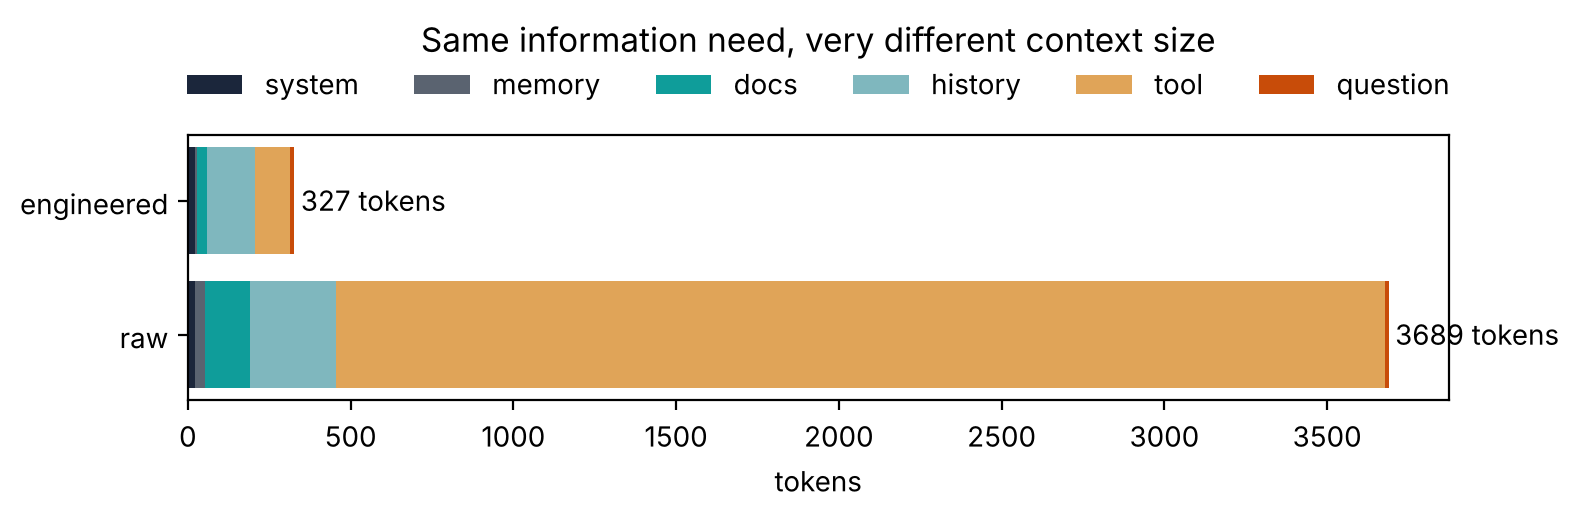

In [9]:
import matplotlib.pyplot as plt
before = {"system": count_tokens(SYSTEM), "memory": count_tokens("\n".join(MEMORY)),
          "docs": count_tokens("\n".join(DOCS.values())), "history": count_tokens("\n".join(HISTORY)),
          "tool": count_tokens(TOOL_OUTPUT), "question": count_tokens(QUESTION)}
after = {"system": count_tokens(SYSTEM), "memory": count_tokens("\n".join(recall(MEMORY, QUESTION))),
         "docs": count_tokens(DOCS["payments-policy"]), "history": count_tokens("\n".join(rule_based)),
         "tool": count_tokens(TOOL_SHORT), "question": count_tokens(QUESTION)}
colors = ["#1B263B", "#5A6370", "#0F9D9A", "#7FB7BE", "#E0A458", "#C84C09"]
fig, ax = plt.subplots(figsize=(8, 2.8))
for row, (name, d) in enumerate([("raw", before), ("engineered", after)]):
    left = 0
    for (k, v), c in zip(d.items(), colors):
        ax.barh(row, v, left=left, color=c, label=k if row == 0 else None)
        left += v
    ax.text(left + 20, row, f"{left} tokens", va="center")
ax.set_yticks([0, 1], ["raw", "engineered"]); ax.set_xlabel("tokens")
ax.legend(ncol=6, loc="upper center", bbox_to_anchor=(0.5, 1.35), frameon=False)
ax.set_title("Same information need, very different context size", pad=30)
plt.tight_layout(); plt.show()

## 8. Use the engineered context

Finally, we send the packed context to the model as the user message. (The answer quality depends on the model; the *context* is now small, relevant and well-labelled, which helps every model.)

In [10]:
answer = call_llm(SYSTEM, context + "\n\nAnswer the question in the <question> block.", max_tokens=60)
print(answer)

<system id="rules">
You are Sprout, Brightleaf's support assistant. Answer briefly. Cite the policy id in brackets.
</system>

<doc id="payment-log">
2026-11-20 07:00 payment


## Recap
- The context window is a **budget**: measure tokens.
- **Trim** tool output (keep head and tail), **summarise** old history, **recall** only relevant memory.
- **Pack by priority**, then **order for reading**: stable rules first, question last, each block tagged.
- Smaller, relevant context is cheaper, faster and usually more accurate.

**Try it:** lower the budget to 250 and see what is dropped first. Is that the right thing to drop? Change the priorities to fix it.